In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [107]:
df = pd.read_csv('/content/drive/MyDrive/air_pollution_data.csv')

df.head(10)

,city,date,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3
0,Ahmedabad,30-11-2020,5,520.71,2.38,16.28,130.18,47.68,65.96,72.13,8.36
1,Ahmedabad,01-12-2020,5,1682.28,7.71,54.84,0.73,21.70,120.95,154.53,27.36
2,Ahmedabad,02-12-2020,5,1815.80,16.54,49.35,0.17,23.84,133.47,172.63,28.12
3,Ahmedabad,03-12-2020,5,2296.45,41.57,40.10,0.00,35.76,150.37,202.15,36.48
4,Ahmedabad,04-12-2020,5,2189.64,23.92,58.95,0.02,28.13,160.79,205.80,40.53
5,Ahmedabad,05-12-2020,5,3845.22,57.22,137.09,0.00,110.63,249.51,322.46,178.34
6,Ahmedabad,06-12-2020,5,2883.91,27.94,98.71,0.02,84.88,232.03,281.96,96.26
7,Ahmedabad,07-12-2020,5,1628.88,19.89,40.10,0.02,21.22,106.27,143.12,31.67
8,Ahmedabad,08-12-2020,5,1735.69,9.28,59.63,0.59,25.99,122.37,163.42,43.06
9,Ahmedabad,09-12-2020,5,2857.21,34.87,69.92,0.00,46.25,213.63,276.18,58.77


In [108]:
df.shape

(23504, 11)

In [109]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23504 entries, 0 to 23503
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    23504 non-null  object 
 1   date    23504 non-null  object 
 2   aqi     23504 non-null  int64  
 3   co      23504 non-null  float64
 4   no      23504 non-null  float64
 5   no2     23504 non-null  float64
 6   o3      23504 non-null  float64
 7   so2     23504 non-null  float64
 8   pm2_5   23504 non-null  float64
 9   pm10    23504 non-null  float64
 10  nh3     23504 non-null  float64
dtypes: float64(8), int64(1), object(2)
memory usage: 2.0+ MB


In [110]:
print(df.columns)

Index(['city', 'date', 'aqi', 'co', 'no', 'no2', 'o3', 'so2', 'pm2_5', 'pm10',
       'nh3'],
      dtype='object')


In [111]:
df.isnull().sum()

,0
city,0
date,0
aqi,0
co,0
no,0
no2,0
o3,0
so2,0
pm2_5,0
pm10,0


In [112]:
df.isnull().sum()

,0
city,0
date,0
aqi,0
co,0
no,0
no2,0
o3,0
so2,0
pm2_5,0
pm10,0


In [113]:
df = df.drop_duplicates()

In [114]:
df.shape

(23504, 11)

In [115]:
print(df.describe())

                aqi            co           no           no2            o3  \
count  23504.000000  23504.000000  23504.00000  23504.000000  23504.000000   
mean       3.920354   1113.224543      6.00554     25.044104     35.059777   
std        1.415490   1401.770372     24.50272     25.839242     31.901760   
min        1.000000    173.570000      0.00000      0.310000      0.000000   
25%        3.000000    447.270000      0.00000      8.740000      7.870000   
50%        5.000000    700.950000      0.00000     16.450000     28.250000   
75%        5.000000   1188.280000      0.27000     32.220000     54.360000   
max        5.000000  23071.290000    457.76000    331.760000    406.270000   

                so2         pm2_5          pm10           nh3  
count  23504.000000  23504.000000  23504.000000  23504.000000  
mean      15.971449     98.598310    121.848091     12.060212  
std       23.943464    135.572391    160.429589     17.544759  
min        0.190000      0.500000      0.

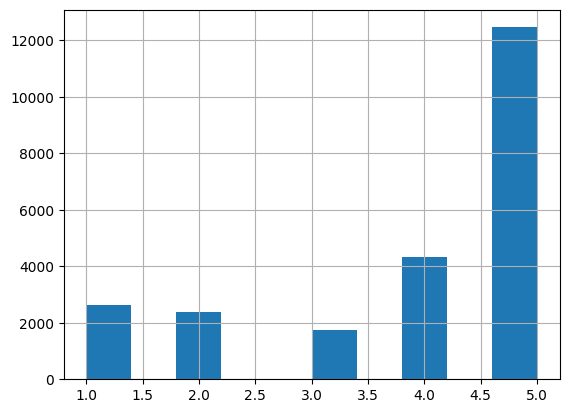

In [116]:
df['aqi'].hist()
plt.show()

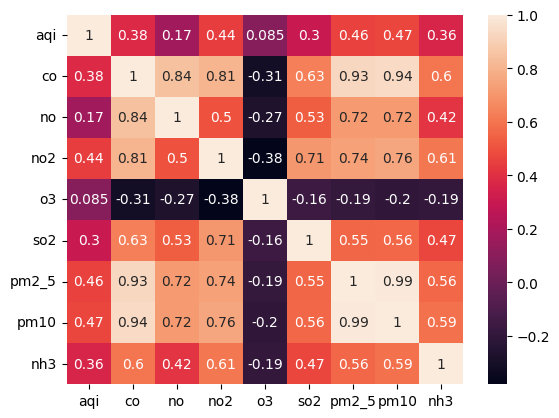

In [117]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True)
plt.show()

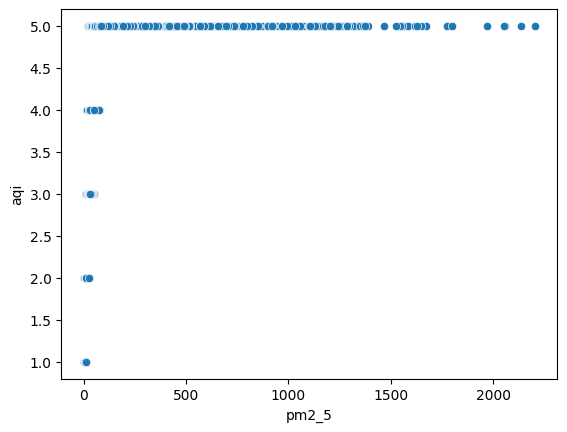

In [118]:
sns.scatterplot(x='pm2_5', y='aqi', data=df)
plt.show()

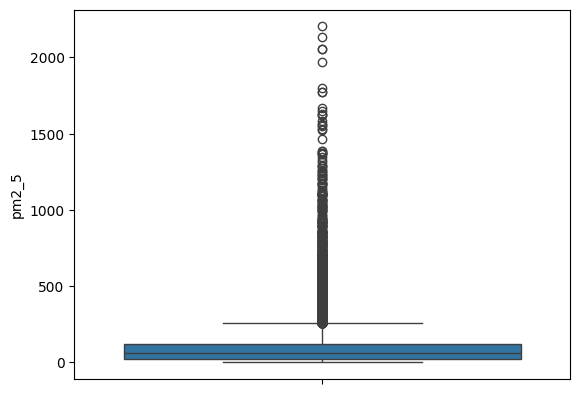

In [119]:
sns.boxplot(df['pm2_5'])
plt.show()

In [120]:
Q1 = df['pm2_5'].quantile(0.25)
Q3 = df['pm2_5'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_ = df[(df['pm2_5'] >= lower) & (df['pm2_5'] <= upper)]

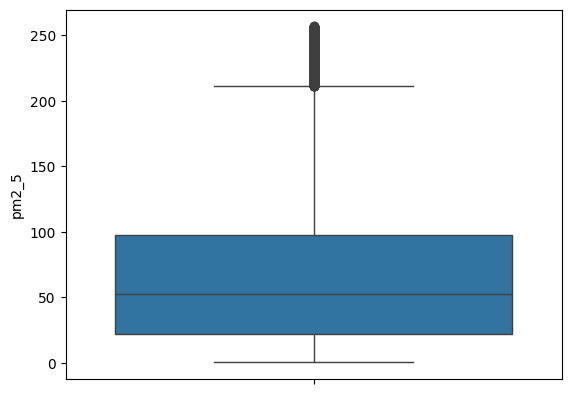

In [121]:
sns.boxplot(df_['pm2_5'])
plt.show()

<Axes: xlabel='pm2_5', ylabel='aqi'>

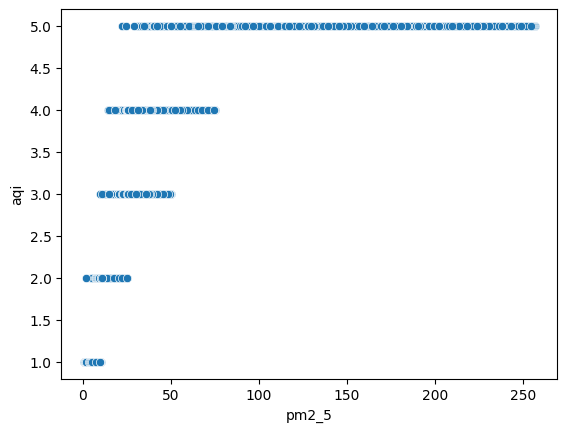

In [122]:
sns.scatterplot(x='pm2_5', y='aqi', data=df_)

In [123]:
print("Original Shape:", df.shape)
print("New Shape:", df_.shape)

Original Shape: (23504, 11)
New Shape: (21654, 11)


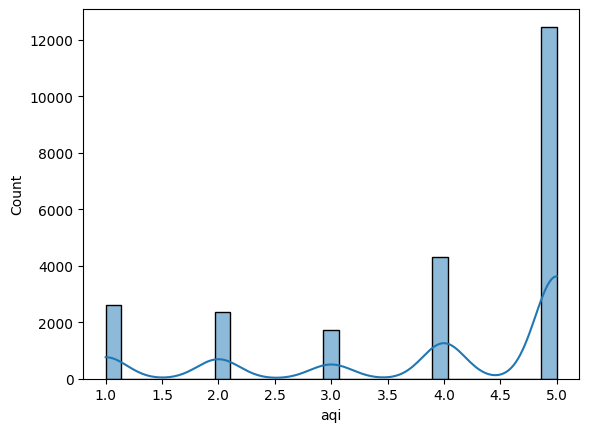

In [ ]:
sns.histplot(df['aqi'], kde=True)
plt.show()

In [130]:
df_['date'] = pd.to_datetime(df_['date'])
df_['day_of_week'] = df_['date'].dt.dayofweek
df_['is_weekend'] = df_['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

/tmp/ipykernel_15985/1108484318.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_['date'] = pd.to_datetime(df_['date'])
/tmp/ipykernel_15985/1108484318.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_['day_of_week'] = df_['date'].dt.dayofweek
/tmp/ipykernel_15985/1108484318.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/panda

In [129]:
df_.head()

,city,date,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3,day_of_week,is_weekend
0,Ahmedabad,2020-11-30,5,520.71,2.38,16.28,130.18,47.68,65.96,72.13,8.36,0,0
1,Ahmedabad,2020-12-01,5,1682.28,7.71,54.84,0.73,21.70,120.95,154.53,27.36,1,0
2,Ahmedabad,2020-12-02,5,1815.80,16.54,49.35,0.17,23.84,133.47,172.63,28.12,2,0
3,Ahmedabad,2020-12-03,5,2296.45,41.57,40.10,0.00,35.76,150.37,202.15,36.48,3,0
4,Ahmedabad,2020-12-04,5,2189.64,23.92,58.95,0.02,28.13,160.79,205.80,40.53,4,0


In [148]:
from sklearn.model_selection import train_test_split

# Define Features (X) and Target (y)
X = df_.drop(['aqi','date','city','nh3','is_weekend','day_of_week','no'], axis=1) # Assuming 'AQI' is your target column
y = df_['aqi']

# Split the data (80% train, 20% test is common)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [149]:
print(X.columns)
y.info()

Index(['co', 'no2', 'o3', 'so2', 'pm2_5', 'pm10'], dtype='object')
<class 'pandas.core.series.Series'>
Index: 21654 entries, 0 to 23503
Series name: aqi
Non-Null Count  Dtype
--------------  -----
21654 non-null  int64
dtypes: int64(1)
memory usage: 854.4 KB


In [150]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test) # Important: Use transform, not fit_transform on test data

In [151]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Support Vector Machine': SVR()
}

# Dictionary to store results
results = {}

# Train and evaluate each model
for name, model in models.items():
    # Train the model
    model.fit(X_train_scaled, y_train)

    # Make predictions on the test set
    y_pred = model.predict(X_test_scaled)

    # Calculate metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Store results
    results[name] = {'MAE': mae, 'MSE': mse, 'R2': r2}

    # Print results
    print(f"--- {name} ---")
    print(f"MAE: {mae:.2f}")
    print(f"MSE: {mse:.2f}")
    print(f"R2 Score: {r2:.2f}\n")

--- Linear Regression ---
MAE: 0.83
MSE: 0.93
R2 Score: 0.55

--- Random Forest ---
MAE: 0.12
MSE: 0.06
R2 Score: 0.97

--- Support Vector Machine ---
MAE: 0.24
MSE: 0.13
R2 Score: 0.94



In [156]:
# Train model
model = RandomForestRegressor()

model.fit(X_train, y_train)

RandomForestRegressor()

In [155]:
# Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

MAE: 0.2357081548778212
MSE: 0.13383890342262017
R2 Score: 0.9359583323119393


In [154]:
import joblib


# Save model
joblib.dump(model, 'aqi_model.pkl')

joblib.dump(scaler, 'scaler.pkl')
print("Model Saved Successfully")

Model Saved Successfully
